# PCPP

In [1]:
import numpy as np

def sample_pcpp(n, theta, omega, random_state=None):
    if n < 1:
        raise ValueError("n debe ser positivo.")
    if theta <= 0:
        raise ValueError("theta debe ser positivo.")
    if not 0 <= omega <= 1:
        raise ValueError("omega debe pertenecer a [0, 1].")

    rng = np.random.default_rng(random_state)

    # 1. Número de comunidades potenciales
    M = 1 + rng.poisson(theta)

    # 2. Torneo aleatorio
    D = np.zeros(M, dtype=int)
    tournament = []

    for j in range(M):
        for l in range(j + 1, M):
            win = rng.binomial(1, 0.5)

            if win == 1:
                D[j] += 1
                winner, loser = j, l
            else:
                D[l] += 1
                winner, loser = l, j

            tournament.append((winner, loser))

    # 3. Pesos de asignación
    W = (1 - omega) / M + omega * (1 + 2 * D) / M**2

    # 4. Asignación de los n elementos
    xi = rng.choice(M, size=n, p=W)

    # 5. Partición inducida
    labels, inverse, counts = np.unique(
        xi, return_inverse=True, return_counts=True
    )

    blocks = [
        np.where(inverse == k)[0].tolist()
        for k in range(len(labels))
    ]

    return {
        "M": M,
        "D": D,
        "W": W,
        "tournament": tournament,
        "xi_raw": xi,
        "canonical_xi": inverse,
        "K_n": len(labels),
        "block_sizes": counts.tolist(),
        "blocks": blocks
    }

# Visualizar una realización de la PCPP

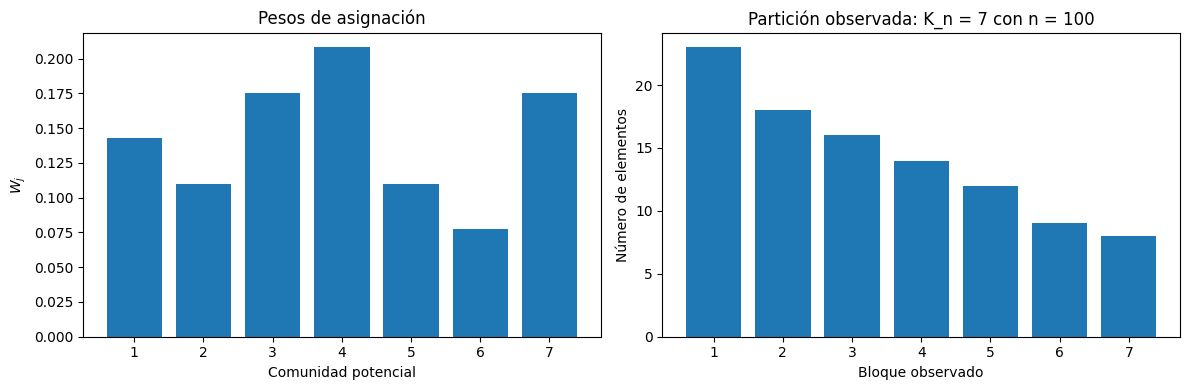

Número de comunidades potenciales: 7
Victorias por comunidad: [3 2 4 5 2 1 4]
Pesos: [0.143 0.11  0.176 0.208 0.11  0.078 0.176]
Tamaños de los bloques: [14, 12, 18, 23, 16, 8, 9]


In [8]:

import matplotlib.pyplot as plt

res = sample_pcpp(
    n=100,
    theta=4,
    omega=0.8,
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pesos de las comunidades potenciales
axes[0].bar(
    np.arange(res["M"]) + 1,
    res["W"]
)
axes[0].set(
    title="Pesos de asignación",
    xlabel="Comunidad potencial",
    ylabel=r"$W_j$"
)

# Tamaños de los bloques observados
axes[1].bar(
    np.arange(1, res["K_n"] + 1),
    sorted(res["block_sizes"], reverse=True)
)
axes[1].set(
    title=f"Partición observada: K_n = {res['K_n']} con n = 100",
    xlabel="Bloque observado",
    ylabel="Número de elementos"
)

plt.tight_layout()
plt.show()

print("Número de comunidades potenciales:", res["M"])
print("Victorias por comunidad:", res["D"])
print("Pesos:", np.round(res["W"], 3))
print("Tamaños de los bloques:", res["block_sizes"])

# Efecto de $\omega$

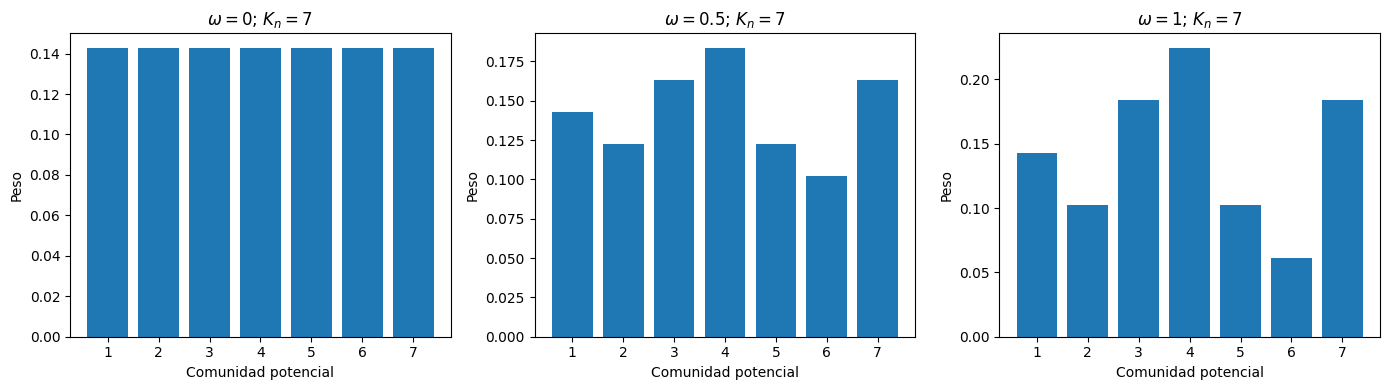

In [7]:

thetas = [4]
omegas = [0, 0.5, 1]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, omega in zip(axes, omegas):
    res = sample_pcpp(
        n=100,
        theta=4,
        omega=omega,
        random_state=42
    )

    ax.bar(np.arange(1, res["M"] + 1), res["W"])
    ax.set_title(
        rf"$\omega={omega}$; $K_n={res['K_n']}$"
    )
    ax.set_xlabel("Comunidad potencial")
    ax.set_ylabel("Peso")

plt.tight_layout()
plt.show()

# Efecto de $\theta$

In [6]:

import pandas as pd

def monte_carlo_pcpp(n, theta, omega, B=1000, seed=123):
    rng = np.random.default_rng(seed)
    K_values = []

    for _ in range(B):
        res = sample_pcpp(
            n=n,
            theta=theta,
            omega=omega,
            random_state=int(rng.integers(0, 2**32))
        )
        K_values.append(res["K_n"])

    return np.array(K_values)


thetas = [0.5, 1, 2, 4, 8, 12]
n = 100
omega = 0.7
B = 1000

results = []

for theta in thetas:
    K = monte_carlo_pcpp(
        n=n,
        theta=theta,
        omega=omega,
        B=B,
        seed=123
    )

    results.append({
        "theta": theta,
        "E_K_n_estimada": K.mean(),
        "Desviacion_estandar": K.std(ddof=1),
        "Mediana": np.median(K),
        "Minimo": K.min(),
        "Maximo": K.max()
    })

df = pd.DataFrame(results)
print(df.round(3))

   theta  E_K_n_estimada  Desviacion_estandar  Mediana  Minimo  Maximo
0    0.5           1.501                0.726      1.0       1       5
1    1.0           2.010                1.045      2.0       1       8
2    2.0           3.029                1.449      3.0       1       8
3    4.0           5.029                2.045      5.0       1      14
4    8.0           9.045                2.854      9.0       1      18
5   12.0          13.015                3.538     13.0       2      27
